# DS471 Machine Learning Project: Breast Cancer Classification

Dataset: UCI Breast Cancer Wisconsin (Diagnostic), 569 samples, 30 numerical features, target = diagnosis (M = Malignant, B = Benign).
Models: Logistic Regression, Random Forest and a Neural Network (multilayer perceptron).

## Stage 1: Data cleaning, preparation and exploration

In [1]:
!pip install kagglehub

In [2]:
# 1. Import necessary libraries
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

In [3]:
# 2. Download and Load the dataset
path = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")
print("Path to dataset files:", path)
# Read the CSV file from the downloaded path
csv_path = os.path.join(path, "data.csv")
df = pd.read_csv(csv_path)

print("\n--- Initial Data Info ---")
print(df.info())

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.
Path to dataset files: /kaggle/input/breast-cancer-wisconsin-data

--- Initial Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dime

In [4]:
# 3. Data Cleaning
if 'id' in df.columns:
    df.drop('id', axis=1, inplace=True)
if 'Unnamed: 32' in df.columns:
    df.drop('Unnamed: 32', axis=1, inplace=True)

In [5]:
# 4. Encoding the target variable
le = LabelEncoder()
df['diagnosis'] = le.fit_transform(df['diagnosis'])

print("\n--- Target Distribution ---")
print(df['diagnosis'].value_counts())


--- Target Distribution ---
diagnosis
0    357
1    212
Name: count, dtype: int64


/tmp/ipykernel_630/3040900174.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='diagnosis', data=df, palette='Set2')


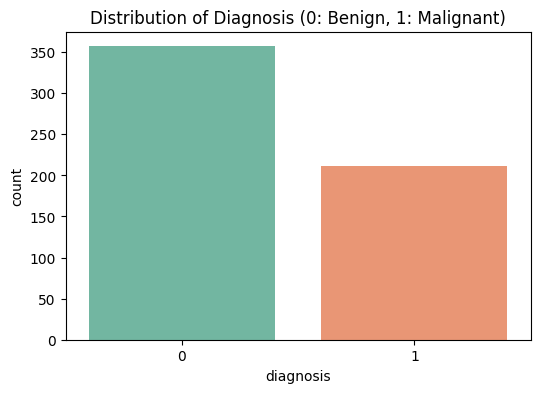

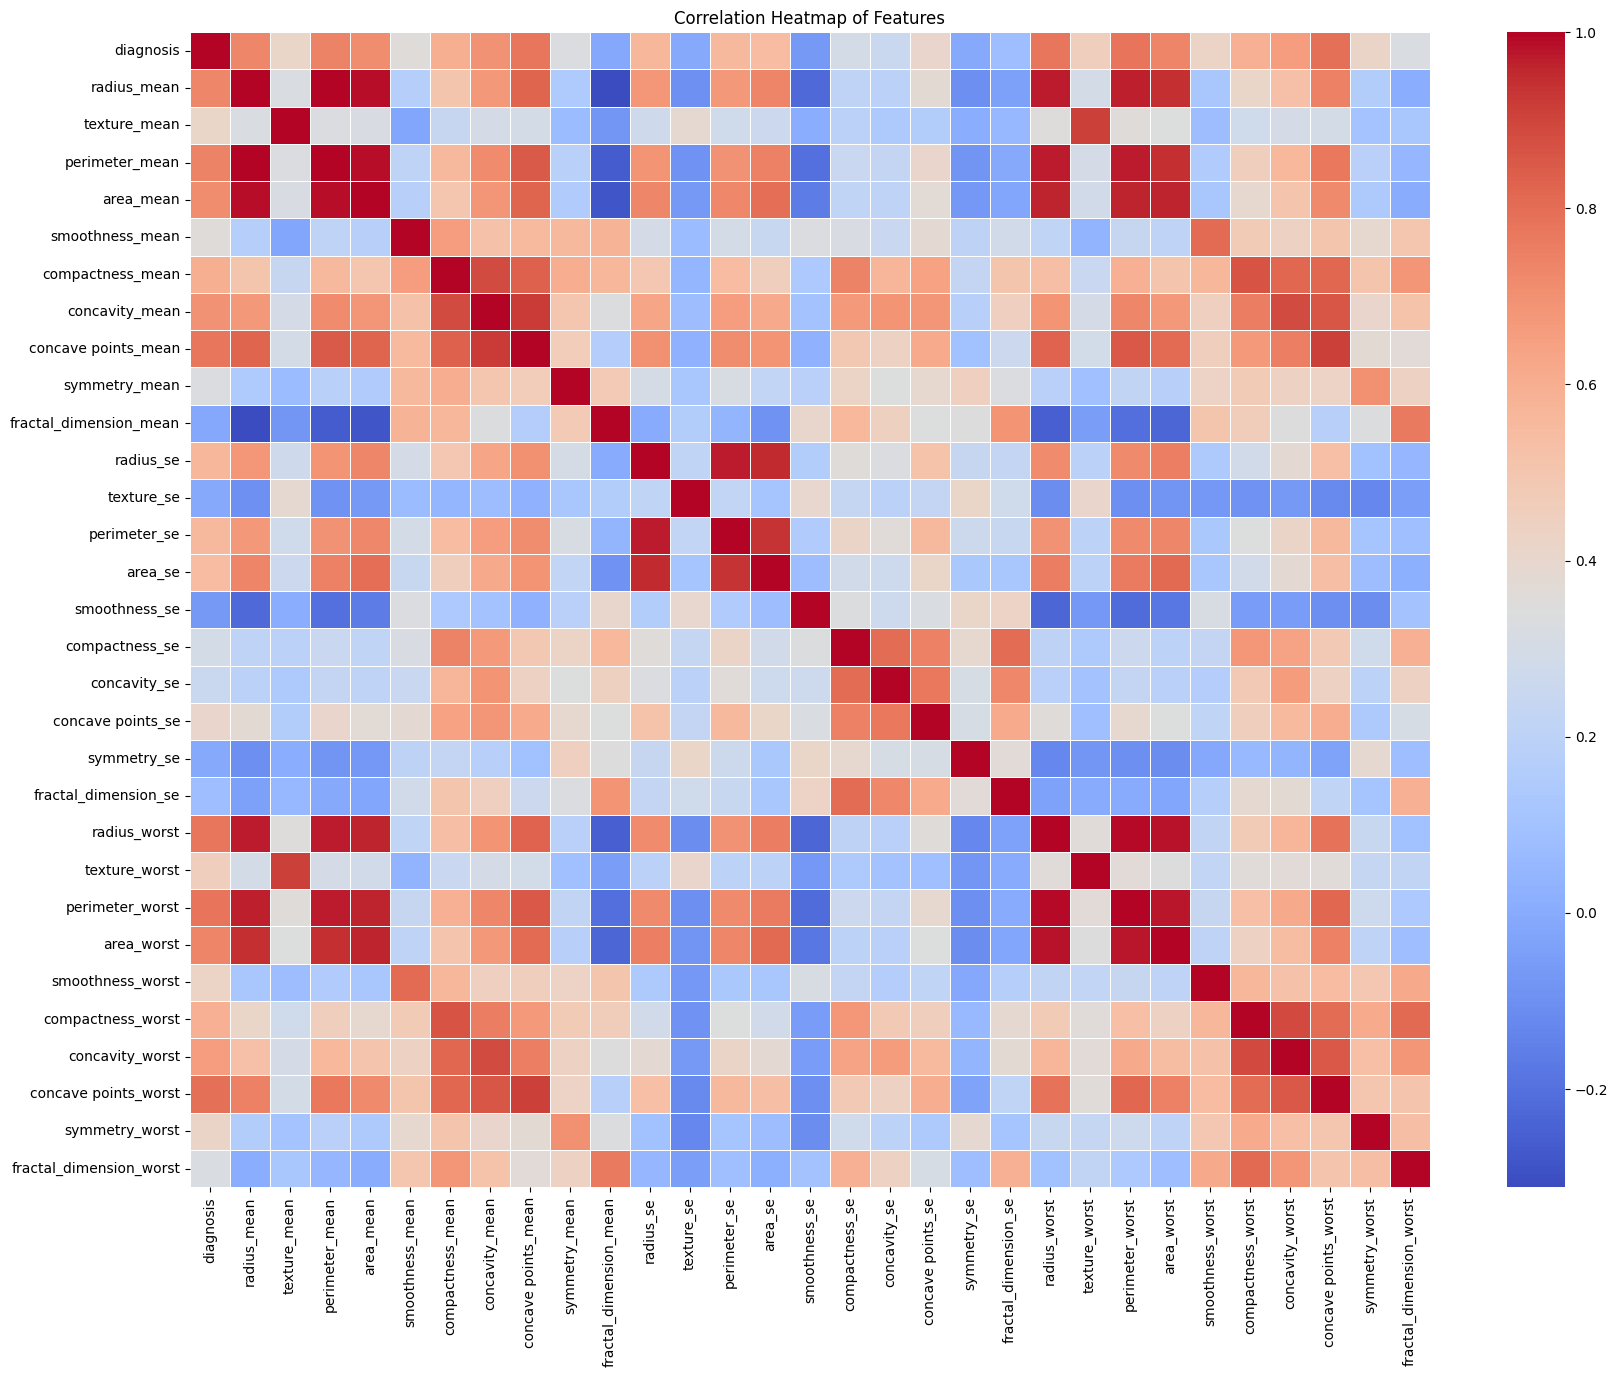

In [6]:
# 5. Exploratory Data Analysis (EDA)
plt.figure(figsize=(6, 4))
sns.countplot(x='diagnosis', data=df, palette='Set2')
plt.title('Distribution of Diagnosis (0: Benign, 1: Malignant)')
plt.show()

plt.figure(figsize=(20, 15))
corr_matrix = df.corr()
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap of Features')
plt.show()

In [7]:
# 6. Separating Features (X) and Target (y)
X = df.drop('diagnosis', axis=1)
y = df['diagnosis']

### Data quality checks and feature-selection decision

In [8]:
# 7. Data quality checks: missing values, duplicates and outliers
print("Missing values (all columns):", int(df.isnull().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

# Outliers with the IQR rule (1.5 x IQR) on the 30 features
Q1, Q3 = X.quantile(0.25), X.quantile(0.75)
IQR = Q3 - Q1
is_outlier = (X < Q1 - 1.5 * IQR) | (X > Q3 + 1.5 * IQR)
print("\nFeatures with at least one outlier:", int((is_outlier.sum() > 0).sum()), "of", X.shape[1])
print("Rows with at least one outlier value:", int(is_outlier.any(axis=1).sum()), "of", len(X))
print("\nTop 5 features by number of outliers:")
print(is_outlier.sum().sort_values(ascending=False).head(5))
print("\nOutlier share per class (rows with >= 1 outlier):")
print(is_outlier.any(axis=1).groupby(y).mean().round(3).rename({0: "Benign", 1: "Malignant"}))

Missing values (all columns): 0
Duplicate rows: 0

Features with at least one outlier: 29 of 30
Rows with at least one outlier value: 171 of 569

Top 5 features by number of outliers:
area_se          65
radius_se        38
perimeter_se     38
area_worst       35
smoothness_se    30
dtype: int64

Outlier share per class (rows with >= 1 outlier):
diagnosis
Benign       0.160
Malignant    0.538
dtype: float64


In [9]:
# 8. Correlation analysis and feature-selection decision
corr = X.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_pairs = upper.stack()
high_pairs = high_pairs[high_pairs > 0.90].sort_values(ascending=False)
print("Feature pairs with |r| > 0.90:", len(high_pairs))
print(high_pairs.head(8).round(3))

target_corr = X.corrwith(y).sort_values(ascending=False)
print("\nTop 6 features by correlation with the target (Malignant = 1):")
print(target_corr.head(6).round(3))

print("\nDecision: all 30 features are kept (see the report, Stage 1 - Feature Selection).")

Feature pairs with |r| > 0.90: 21
radius_mean      perimeter_mean     0.998
radius_worst     perimeter_worst    0.994
radius_mean      area_mean          0.987
perimeter_mean   area_mean          0.987
radius_worst     area_worst         0.984
perimeter_worst  area_worst         0.978
radius_se        perimeter_se       0.973
perimeter_mean   perimeter_worst    0.970
dtype: float64

Top 6 features by correlation with the target (Malignant = 1):
concave points_worst    0.794
perimeter_worst         0.783
concave points_mean     0.777
radius_worst            0.776
perimeter_mean          0.743
area_worst              0.734
dtype: float64

Decision: all 30 features are kept (see the report, Stage 1 - Feature Selection).


## Stage 2: Data splitting (70% / 15% / 15%, stratified) and scaling

In [10]:
# ==========================================
# Stage 2: Data Splitting (MUST happen before Scaling)
# ==========================================

# Step 1: Extract 15% for Test set
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.15, stratify=y, random_state=42)

# Step 2: Extract 15% (of total) for Validation set
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=(0.15/0.85), stratify=y_temp, random_state=42)

print("\n--- Data Splitting Results ---")
print(f"Total dataset size: {len(X)}")
print(f"Training set size: {len(X_train)} ({len(X_train)/len(X)*100:.1f}%)")
print(f"Validation set size: {len(X_val)} ({len(X_val)/len(X)*100:.1f}%)")
print(f"Test set size: {len(X_test)} ({len(X_test)/len(X)*100:.1f}%)")

# ==========================================
# Feature Scaling (applied AFTER splitting)
# ==========================================

scaler = StandardScaler()

# Fit and transform ONLY on training data
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)

# Only transform validation and test data (DO NOT fit)
X_val_scaled = pd.DataFrame(scaler.transform(X_val), columns=X_val.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

print("\n--- Scaling Completed Successfully (No Data Leakage) ---")


--- Data Splitting Results ---
Total dataset size: 569
Training set size: 397 (69.8%)
Validation set size: 86 (15.1%)
Test set size: 86 (15.1%)

--- Scaling Completed Successfully (No Data Leakage) ---


## Stage 3: Model selection and development

Logistic Regression (linear baseline), Random Forest (non-linear ensemble) and a Neural Network (mandatory). All models use the same scaled inputs. First the traditional models are trained with default hyperparameters.

In [11]:
# 9. Stage 3: Baseline models (default hyperparameters)
import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, validation_curve, learning_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve, log_loss)

def split_scores(model):
    """Accuracy, F1 and Recall (Malignant = positive class) on the train and validation sets."""
    out = {}
    for name, (Xs, ys) in {"Train": (X_train_scaled, y_train), "Val": (X_val_scaled, y_val)}.items():
        pred = model.predict(Xs)
        out[f"{name} Acc"] = accuracy_score(ys, pred)
        out[f"{name} F1"] = f1_score(ys, pred)
        if name == "Val":
            out["Val Recall"] = recall_score(ys, pred)
    return out

lr_base = LogisticRegression(max_iter=10000, random_state=42).fit(X_train_scaled, y_train)
rf_base = RandomForestClassifier(random_state=42).fit(X_train_scaled, y_train)

baseline = pd.DataFrame({"Logistic Regression": split_scores(lr_base),
                         "Random Forest": split_scores(rf_base)}).T.round(4)
print("Table 1: Baseline performance (default hyperparameters)")
print(baseline)

Table 1: Baseline performance (default hyperparameters)
                     Train Acc  Train F1  Val Acc  Val F1  Val Recall
Logistic Regression     0.9824    0.9759   0.9767  0.9688      0.9688
Random Forest           1.0000    1.0000   0.9651  0.9524      0.9375


## Stage 4: Model training and hyperparameter optimization

GridSearchCV with 5-fold stratified cross-validation on the **training set only**; the selection metric is the F1-score of the Malignant class (Recall is tracked as well).

In [12]:
# 10. Stage 4: Hyperparameter tuning of Logistic Regression (5-fold stratified CV on the training set)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lr_grid = {"C": [0.001, 0.01, 0.1, 1, 10, 100],
           "penalty": ["l1", "l2"],
           "class_weight": [None, "balanced"]}
lr_search = GridSearchCV(LogisticRegression(solver="liblinear", max_iter=10000, random_state=42),
                         lr_grid, scoring={"f1": "f1", "recall": "recall"}, refit="f1",
                         cv=cv, return_train_score=True)
lr_search.fit(X_train_scaled, y_train)

i = lr_search.best_index_
print("Combinations searched:", len(lr_search.cv_results_["params"]))
print("Best parameters:", lr_search.best_params_)
print("CV F1 (train folds): %.4f | CV F1 (validation folds): %.4f | CV Recall: %.4f" % (
    lr_search.cv_results_["mean_train_f1"][i], lr_search.cv_results_["mean_test_f1"][i],
    lr_search.cv_results_["mean_test_recall"][i]))
lr_best = lr_search.best_estimator_

Combinations searched: 24
Best parameters: {'C': 0.1, 'class_weight': 'balanced', 'penalty': 'l2'}
CV F1 (train folds): 0.9711 | CV F1 (validation folds): 0.9660 | CV Recall: 0.9598


In [13]:
# 11. Stage 4: Hyperparameter tuning of Random Forest (5-fold stratified CV on the training set)
rf_grid = {"n_estimators": [100, 200, 300],
           "max_depth": [3, 5, 8, None],
           "min_samples_leaf": [1, 2, 4],
           "max_features": ["sqrt", "log2"],
           "class_weight": [None, "balanced"]}
rf_search = GridSearchCV(RandomForestClassifier(random_state=42), rf_grid,
                         scoring={"f1": "f1", "recall": "recall"}, refit="f1",
                         cv=cv, return_train_score=True, n_jobs=-1)
rf_search.fit(X_train_scaled, y_train)

i = rf_search.best_index_
print("Combinations searched:", len(rf_search.cv_results_["params"]))
print("Best parameters:", rf_search.best_params_)
print("CV F1 (train folds): %.4f | CV F1 (validation folds): %.4f | CV Recall: %.4f" % (
    rf_search.cv_results_["mean_train_f1"][i], rf_search.cv_results_["mean_test_f1"][i],
    rf_search.cv_results_["mean_test_recall"][i]))
rf_best = rf_search.best_estimator_
print("Features considered per split (max_features = log2 of 30):", rf_best.estimators_[0].max_features)

Combinations searched: 144
Best parameters: {'class_weight': 'balanced', 'max_depth': 8, 'max_features': 'log2', 'min_samples_leaf': 2, 'n_estimators': 100}
CV F1 (train folds): 0.9941 | CV F1 (validation folds): 0.9488 | CV Recall: 0.9462
Features considered per split (max_features = log2 of 30): log2


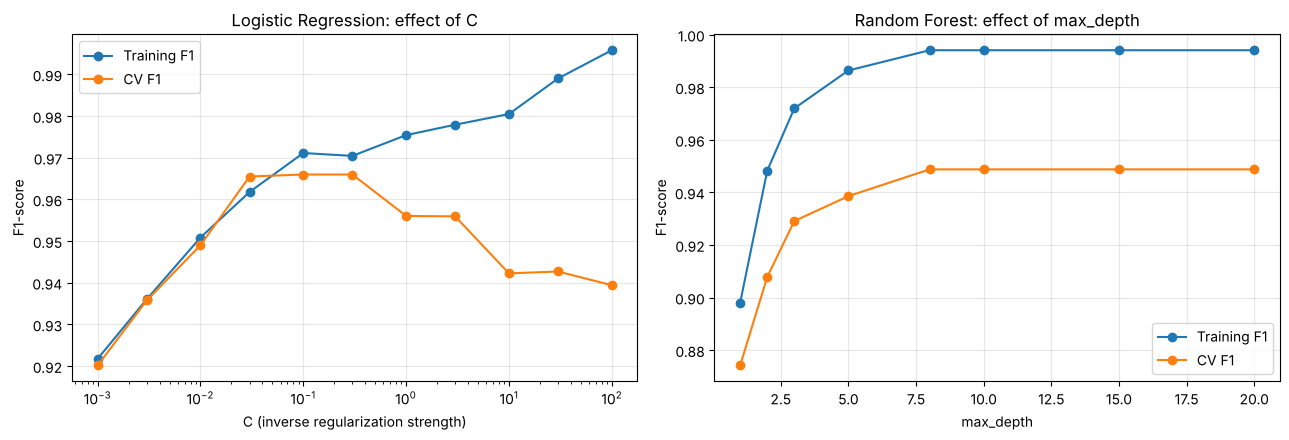

In [14]:
# 12. Figure 1: validation curves (effect of C for Logistic Regression and max_depth for Random Forest)
C_range = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100]
tr_lr, va_lr = validation_curve(
    LogisticRegression(solver="liblinear", penalty="l2", class_weight="balanced", max_iter=10000, random_state=42),
    X_train_scaled, y_train, param_name="C", param_range=C_range, scoring="f1", cv=cv)

depth_range = [1, 2, 3, 5, 8, 10, 15, 20]
rf_params = {k: v for k, v in rf_search.best_params_.items() if k != "max_depth"}
tr_rf, va_rf = validation_curve(
    RandomForestClassifier(random_state=42, **rf_params),
    X_train_scaled, y_train, param_name="max_depth", param_range=depth_range, scoring="f1", cv=cv)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].semilogx(C_range, tr_lr.mean(1), "o-", color="tab:blue", label="Training F1")
ax[0].semilogx(C_range, va_lr.mean(1), "o-", color="tab:orange", label="CV F1")
ax[0].set(title="Logistic Regression: effect of C", xlabel="C (inverse regularization strength)", ylabel="F1-score")
ax[1].plot(depth_range, tr_rf.mean(1), "o-", color="tab:blue", label="Training F1")
ax[1].plot(depth_range, va_rf.mean(1), "o-", color="tab:orange", label="CV F1")
ax[1].set(title="Random Forest: effect of max_depth", xlabel="max_depth", ylabel="F1-score")
for a in ax:
    a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()

Table 4: Training vs validation performance
             Train Acc  Train F1  Val Acc  Val F1  Val Recall  Gap (Train - Val F1)
LR baseline     0.9824    0.9759   0.9767  0.9688      0.9688                0.0072
LR tuned        0.9773    0.9695   0.9767  0.9697      1.0000               -0.0002
RF baseline     1.0000    1.0000   0.9651  0.9524      0.9375                0.0476
RF tuned        0.9950    0.9932   0.9651  0.9524      0.9375                0.0409


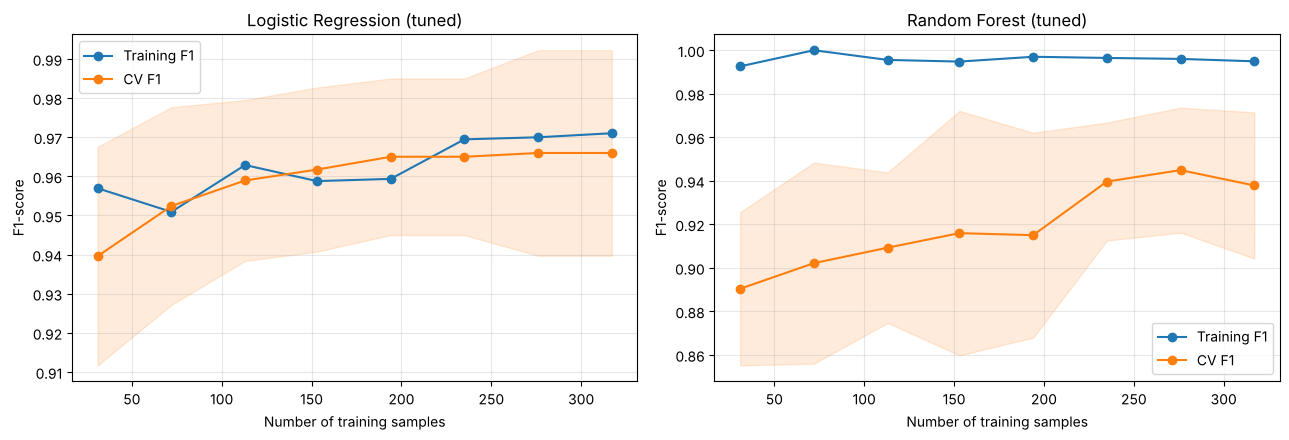

In [15]:
# 13. Table 4: training vs validation performance before and after tuning
compare = pd.DataFrame({"LR baseline": split_scores(lr_base), "LR tuned": split_scores(lr_best),
                        "RF baseline": split_scores(rf_base), "RF tuned": split_scores(rf_best)}).T
compare["Gap (Train - Val F1)"] = compare["Train F1"] - compare["Val F1"]
print("Table 4: Training vs validation performance")
print(compare.round(4))

# Figure 2: learning curves of the tuned models
sizes = np.linspace(0.1, 1.0, 8)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, (name, model) in zip(ax, [("Logistic Regression (tuned)", lr_best), ("Random Forest (tuned)", rf_best)]):
    n, tr, va = learning_curve(model, X_train_scaled, y_train, train_sizes=sizes, cv=cv, scoring="f1", random_state=42, shuffle=True)
    a.plot(n, tr.mean(1), "o-", color="tab:blue", label="Training F1")
    a.plot(n, va.mean(1), "o-", color="tab:orange", label="CV F1")
    a.fill_between(n, va.mean(1) - va.std(1), va.mean(1) + va.std(1), color="tab:orange", alpha=0.15)
    a.set(title=name, xlabel="Number of training samples", ylabel="F1-score"); a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.show()

### Neural Network: hyperparameter search and training/validation curves

In [16]:
# 14. Stage 3/4: Neural Network (multilayer perceptron) - hyperparameter search
# Adam optimizer, ReLU hidden layers, sigmoid output and binary cross-entropy (log-loss), 50 epochs, batch size 32.
nn_grid = {"hidden_layer_sizes": [(8,), (16,), (32,), (16, 8), (32, 16)],
           "alpha": [1e-4, 1e-2],                 # L2 penalty
           "learning_rate_init": [1e-3, 1e-2]}
nn_search = GridSearchCV(
    MLPClassifier(activation="relu", solver="adam", batch_size=32, max_iter=50, random_state=42),
    nn_grid, scoring={"f1": "f1", "recall": "recall"}, refit="f1",
    cv=cv, return_train_score=True, n_jobs=-1)
nn_search.fit(X_train_scaled, y_train)

nn_table = pd.DataFrame(nn_search.cv_results_)[["param_hidden_layer_sizes", "param_alpha", "param_learning_rate_init",
                                                 "mean_train_f1", "mean_test_f1", "mean_test_recall", "rank_test_f1"]]
nn_table.columns = ["hidden_layers", "alpha", "learning_rate", "CV train F1", "CV val F1", "CV val Recall", "rank"]
print("Combinations searched:", len(nn_table))
print(nn_table.sort_values("rank").head(6).round(4).to_string(index=False))
print("\nBest parameters:", nn_search.best_params_)

Combinations searched: 20
hidden_layers  alpha  learning_rate  CV train F1  CV val F1  CV val Recall  rank
        (16,) 0.0001          0.010       0.9983     0.9655         0.9531     1
        (16,) 0.0100          0.010       0.9974     0.9655         0.9531     1
         (8,) 0.0100          0.010       0.9949     0.9622         0.9464     3
        (32,) 0.0100          0.010       1.0000     0.9620         0.9464     4
         (8,) 0.0001          0.010       0.9966     0.9590         0.9464     5
        (32,) 0.0100          0.001       0.9762     0.9590         0.9462     6

Best parameters: {'alpha': 0.0001, 'hidden_layer_sizes': (16,), 'learning_rate_init': 0.01}


Epoch 50 -> train loss 0.0090 | val loss 0.0235 | train acc 0.9975 | val acc 0.9884
Lowest validation loss 0.0228 at epoch 47
NN validation: Train Acc=0.9975, Train F1=0.9966, Val Acc=0.9884, Val F1=0.9846, Val Recall=1.0000


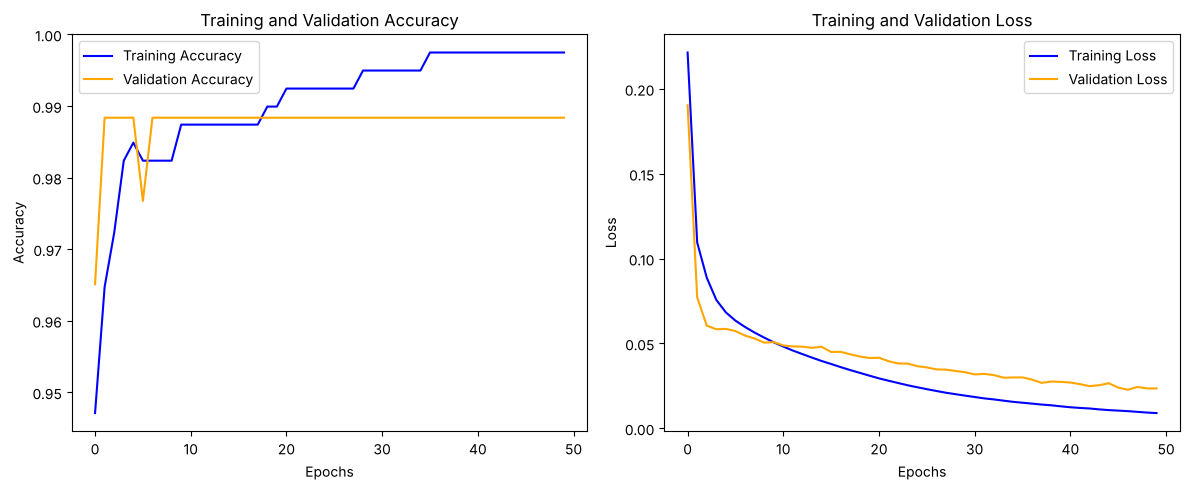

In [17]:
# 15. Train the selected Neural Network epoch by epoch and record training/validation curves
best = nn_search.best_params_
nn = MLPClassifier(hidden_layer_sizes=best["hidden_layer_sizes"], alpha=best["alpha"],
                   learning_rate_init=best["learning_rate_init"], activation="relu", solver="adam",
                   batch_size=32, random_state=42)

history = {"loss": [], "val_loss": [], "accuracy": [], "val_accuracy": []}
for epoch in range(50):
    nn.partial_fit(X_train_scaled, y_train, classes=[0, 1])      # one epoch over the training set
    history["loss"].append(log_loss(y_train, nn.predict_proba(X_train_scaled)))
    history["val_loss"].append(log_loss(y_val, nn.predict_proba(X_val_scaled)))
    history["accuracy"].append(nn.score(X_train_scaled, y_train))
    history["val_accuracy"].append(nn.score(X_val_scaled, y_val))

print("Epoch 50 -> train loss %.4f | val loss %.4f | train acc %.4f | val acc %.4f" % (
    history["loss"][-1], history["val_loss"][-1], history["accuracy"][-1], history["val_accuracy"][-1]))
best_ep = int(np.argmin(history["val_loss"]))
print("Lowest validation loss %.4f at epoch %d" % (history["val_loss"][best_ep], best_ep + 1))
print("NN validation: " + ", ".join(f"{k}={v:.4f}" for k, v in split_scores(nn).items()))

# Figure 5: training and validation curves
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].plot(history["accuracy"], color="blue", label="Training Accuracy")
ax[0].plot(history["val_accuracy"], color="orange", label="Validation Accuracy")
ax[0].set(title="Training and Validation Accuracy", xlabel="Epochs", ylabel="Accuracy"); ax[0].legend()
ax[1].plot(history["loss"], color="blue", label="Training Loss")
ax[1].plot(history["val_loss"], color="orange", label="Validation Loss")
ax[1].set(title="Training and Validation Loss", xlabel="Epochs", ylabel="Loss"); ax[1].legend()
plt.tight_layout(); plt.show()

## Stage 5: Final evaluation and model comparison (test set)

The test set is used only here, once, after all tuning is finished.

Table 5: Test-set performance of all models (86 test samples: 54 Benign, 32 Malignant)
                     Accuracy  Precision  Recall  F1-score  ROC-AUC  Test Loss  False Negatives  False Positives
Model                                                                                                           
Logistic Regression    1.0000        1.0  1.0000    1.0000   1.0000     0.0748                0                0
Random Forest          0.9884        1.0  0.9688    0.9841   1.0000     0.0827                1                0
Neural Network         0.9884        1.0  0.9688    0.9841   0.9867     0.1297                1                0


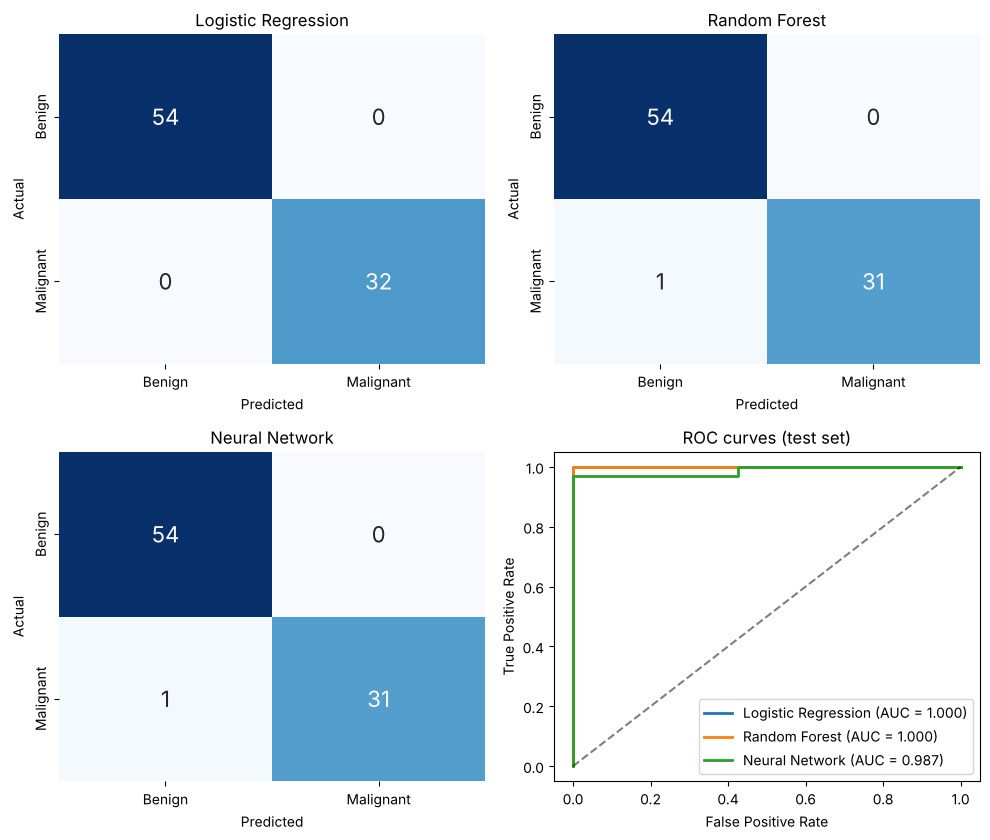

In [18]:
# 16. Stage 5: Final evaluation on the untouched test set (Malignant = positive class)
models = {"Logistic Regression": lr_best, "Random Forest": rf_best, "Neural Network": nn}
rows, cms, rocs = [], {}, {}
for name, m in models.items():
    pred = m.predict(X_test_scaled)
    prob = m.predict_proba(X_test_scaled)[:, 1]
    cms[name] = confusion_matrix(y_test, pred)
    rocs[name] = roc_curve(y_test, prob)
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred), "F1-score": f1_score(y_test, pred),
                 "ROC-AUC": roc_auc_score(y_test, prob), "Test Loss": log_loss(y_test, prob),
                 "False Negatives": int(cms[name][1, 0]), "False Positives": int(cms[name][0, 1])})
results = pd.DataFrame(rows).set_index("Model")
print("Table 5: Test-set performance of all models (86 test samples: 54 Benign, 32 Malignant)")
print(results.round(4))

# Save the results (traditional models keep the original file format)
results.loc[["Logistic Regression", "Random Forest"], ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]] \
       .round(4).reset_index().to_csv("traditional_results.csv", index=False)
results.round(4).reset_index().to_csv("final_results.csv", index=False)

# Figure 3: confusion matrices and ROC curves
fig, axes = plt.subplots(2, 2, figsize=(10, 8.5))
ax = axes.ravel()
for a, (name, cm) in zip(ax[:3], cms.items()):
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a, annot_kws={"size": 16},
                xticklabels=["Benign", "Malignant"], yticklabels=["Benign", "Malignant"])
    a.set(title=f"{name}", xlabel="Predicted", ylabel="Actual")
for name, (fpr, tpr, _) in rocs.items():
    ax[3].plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {results.loc[name, 'ROC-AUC']:.3f})")
ax[3].plot([0, 1], [0, 1], "k--", alpha=0.5)
ax[3].set(title="ROC curves (test set)", xlabel="False Positive Rate", ylabel="True Positive Rate"); ax[3].legend(loc="lower right")
plt.tight_layout(); plt.show()

Top RF features: ['area_worst', 'concave points_worst', 'perimeter_mean', 'perimeter_worst', 'radius_worst']
Top LR coefficients: ['texture_worst (+0.557)', 'radius_se (+0.509)', 'radius_worst (+0.502)', 'perimeter_worst (+0.467)', 'area_worst (+0.456)']


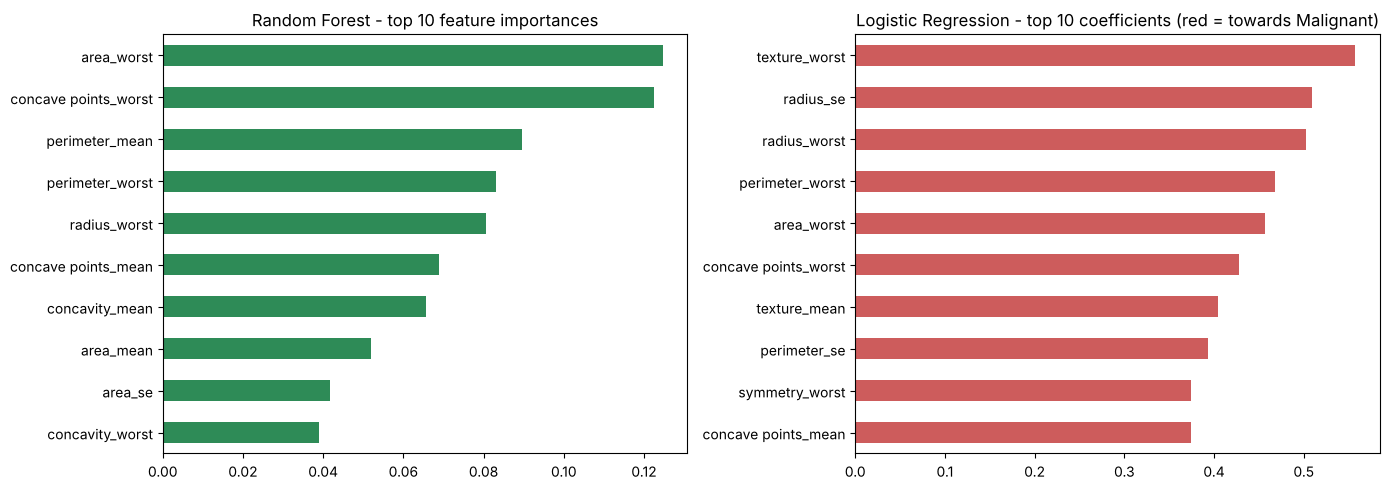

In [19]:
# 17. Figure 4: what the traditional models rely on
imp = pd.Series(rf_best.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
coef = pd.Series(lr_best.coef_[0], index=X.columns)
coef = coef.reindex(coef.abs().sort_values(ascending=False).index).head(10)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
imp[::-1].plot.barh(ax=ax[0], color="seagreen"); ax[0].set_title("Random Forest - top 10 feature importances")
coef[::-1].plot.barh(ax=ax[1], color=["indianred" if v > 0 else "steelblue" for v in coef[::-1]])
ax[1].set_title("Logistic Regression - top 10 coefficients (red = towards Malignant)")
plt.tight_layout(); plt.show()
print("Top RF features:", list(imp.index[:5]))
print("Top LR coefficients:", [f"{k} ({v:+.3f})" for k, v in coef.head(5).items()])